# 2단계 전처리 통합 파이프라인


## 0. 공통 라이브러리 임포트

In [1]:
from pathlib import Path

CUR_DIR = Path.cwd().resolve()
BASE_DIR = CUR_DIR / "data"

In [2]:
import re
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 200)


## Part A. 데이터 로드 + 기본 결측치 처리

In [3]:
INPUT_PATH_A = BASE_DIR / "train_table.pkl"
OUTPUT_PATH_A = BASE_DIR / "2단계_학습데이터_전처리완료.csv"

TARGET_COL = "폐업_다음분기"
QUARTER_COL = "기준_년분기"
ID_COL = "상가업소번호"

RADIUS_DIVERSITY_COLS = ["반경100m_업종다양성", "반경250m_업종다양성"]
RADIUS_NEIGHBOR_COLS = ["반경100m_이웃수", "반경250m_이웃수"]
QUARTER_MEAN_COLS = ["건물내업종다양성_unique", "건물내업종다양성_entropy", "건물내총업소수"]
DROP_COLS_A = ["층수_숫자"]


In [ ]:
from pathlib import Path
import pandas as pd
import gc

BASE_DIR = Path.cwd().resolve() / "data"

INPUT_PATH_A = BASE_DIR / "final" / "train_table.pkl"

print("읽을 파일:", INPUT_PATH_A)
print("파일 존재:", INPUT_PATH_A.exists())


def load_stage2_data(path=INPUT_PATH_A) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(
            f"입력 파일이 없습니다: {path}"
        )

    df_ = pd.read_pickle(path)

    required_cols = [
        TARGET_COL,
        QUARTER_COL,
        ID_COL,
        "반경100m_업종다양성",
        "반경100m_이웃수",
        "반경250m_업종다양성",
        "반경250m_이웃수",
    ]

    missing_cols = [
        c for c in required_cols
        if c not in df_.columns
    ]

    if missing_cols:
        raise ValueError(
            f"현재 읽은 파일에 필수 컬럼이 없습니다: {missing_cols}\n"
            f"읽은 파일: {path}"
        )

    df_[ID_COL] = df_[ID_COL].astype("string")
    df_[QUARTER_COL] = df_[QUARTER_COL].astype("string")

    return df_


try:
    del df
except NameError:
    pass

gc.collect()

df = load_stage2_data()

print("데이터 크기:", df.shape)
print([
    c for c in df.columns
    if "반경" in c
])

읽을 파일: .\data\final\train_table.pkl
파일 존재: True
데이터 크기: (7653982, 57)
['반경100m_업종다양성', '반경100m_이웃수', '반경250m_업종다양성', '반경250m_이웃수']


In [5]:
print(INPUT_PATH_A)
print(INPUT_PATH_A.exists())

print([
    c for c in df.columns
    if "반경" in c
])

.\data\final\train_table.pkl
True
['반경100m_업종다양성', '반경100m_이웃수', '반경250m_업종다양성', '반경250m_이웃수']


In [6]:
df = df.drop(columns=[c for c in DROP_COLS_A if c in df.columns])

for div_col, neighbor_col in zip(RADIUS_DIVERSITY_COLS, RADIUS_NEIGHBOR_COLS):
    mask = df[neighbor_col] == 0
    unexpected = df.loc[mask, div_col].notna().sum()
    if unexpected > 0:
        print(f"[경고] {div_col}: 이웃수=0인데 값이 이미 있는 행 {unexpected}건 - 가정 재확인 필요")
    df.loc[mask, div_col] = df.loc[mask, div_col].fillna(0)
    leftover = df[div_col].isna().sum()
    if leftover > 0:
        print(f"[주의] {div_col}: 0-fill 이후에도 NaN {leftover}건 남음 - 별도 원인 확인 필요")

quarter_means = {}
for col in QUARTER_MEAN_COLS:
    q_mean = df.groupby(QUARTER_COL)[col].transform("mean")
    quarter_means[col] = df.groupby(QUARTER_COL)[col].mean() 
    df[col] = df[col].fillna(q_mean)

check_cols = RADIUS_DIVERSITY_COLS + QUARTER_MEAN_COLS
remaining_na = df[check_cols].isna().sum()
remaining_na = remaining_na[remaining_na > 0]
if len(remaining_na) > 0:
    print("[경고] 처리 후에도 NaN 남음:")
    print(remaining_na)
else:
    print("결측치 처리 완료 - 남은 NaN 없음")


결측치 처리 완료 - 남은 NaN 없음


In [7]:
OUTPUT_PATH_A.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(OUTPUT_PATH_A, index=False, encoding="utf-8-sig")
print(f"체크포인트 저장 완료: {OUTPUT_PATH_A} (총 {len(df)}행)")


체크포인트 저장 완료: .\data\2단계_학습데이터_전처리완료.csv (총 7653982행)


## Part B. 상관관계 점검 (진단용, 선택 실행)

In [8]:
column_summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    '결측수': df.isna().sum(),
    '결측률(%)': df.isna().mean().mul(100),
    '고유값수': df.nunique(dropna=False)
}).sort_values(['결측률(%)', '고유값수'], ascending=[False, False])

display(column_summary)

numeric_cols_all = df.select_dtypes(include=np.number).columns.tolist()
print(f'숫자형 컬럼 수: {len(numeric_cols_all)}')
print(numeric_cols_all)


,dtype,결측수,결측률(%),고유값수
건물관리번호,object,17283,0.225804,178757
표준산업분류명,object,4847,0.063327,455
표준산업분류코드,object,4847,0.063327,412
지번본번지,float64,194,0.002535,2202
건물본번지,float64,117,0.001529,2059
도로명코드,float64,88,0.001150,13141
반경250m_업종다양성,float64,0,0.000000,5225806
반경100m_업종다양성,float64,0,0.000000,2450602
상가업소번호,string,0,0.000000,819025
상호명,object,0,0.000000,589982


숫자형 컬럼 수: 32
['시도코드', '시군구코드', '행정동코드', '법정동코드', '지번코드', '대지구분코드', '지번본번지', '도로명코드', '건물본번지', '구우편번호', '신우편번호', '경도', '위도', '지점여부', '건물명존재여부', '지상1층여부', '지하여부', '반지하여부', '지하층수미상여부', '층호결합추정여부', '층정보파싱실패여부', '층정보결측여부', '건물내총업소수', '건물내업종다양성_unique', '건물내업종다양성_entropy', '건물내표본수부족여부', '건물관리번호결측여부', '반경100m_업종다양성', '반경100m_이웃수', '반경250m_업종다양성', '반경250m_이웃수', '폐업_다음분기']


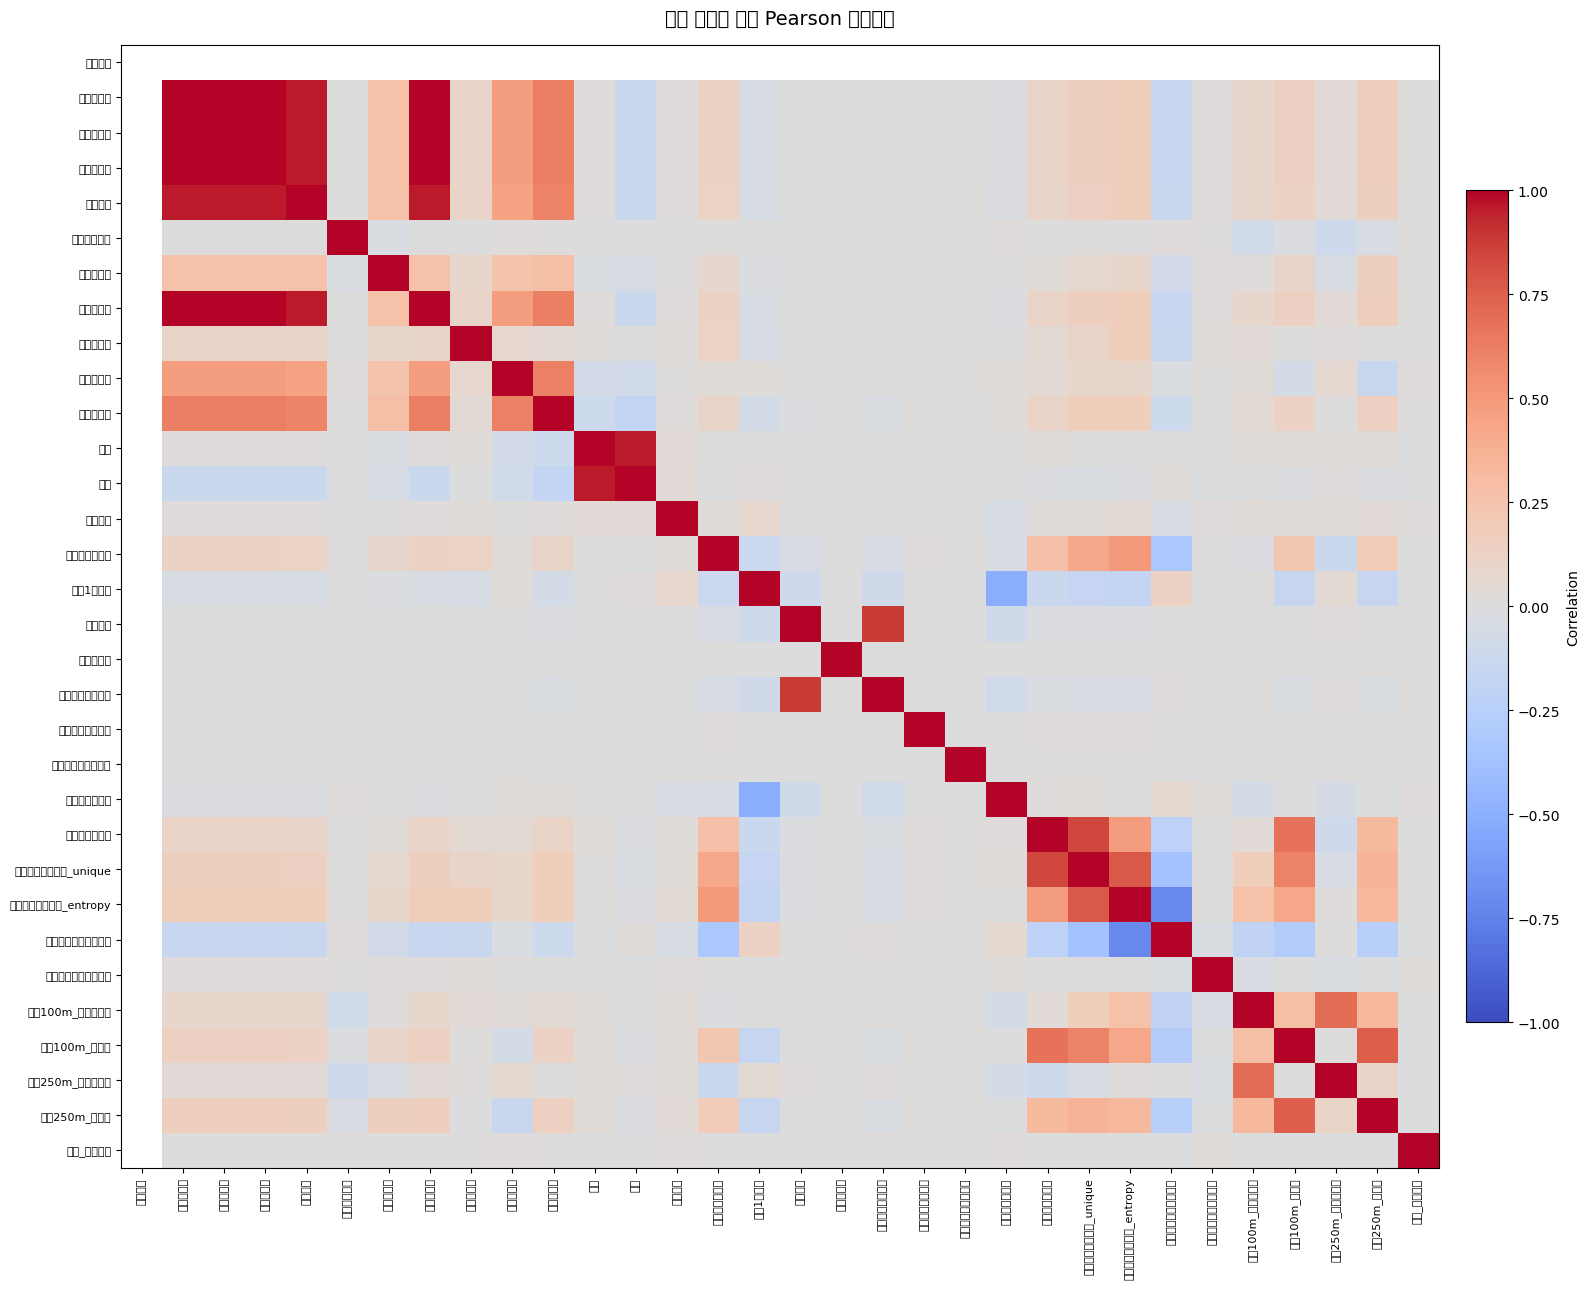

|Pearson r| >= 0.80인 전체 숫자형 변수쌍: 13개


,변수1,변수2,상관계수,절대상관계수
0,시군구코드,법정동코드,1.000000,1.000000
1,행정동코드,법정동코드,1.000000,1.000000
2,시군구코드,행정동코드,1.000000,1.000000
3,시군구코드,도로명코드,0.999998,0.999998
4,법정동코드,도로명코드,0.999998,0.999998
5,행정동코드,도로명코드,0.999998,0.999998
6,행정동코드,지번코드,0.958215,0.958215
7,시군구코드,지번코드,0.958215,0.958215
8,법정동코드,지번코드,0.958215,0.958215
9,지번코드,도로명코드,0.958214,0.958214


In [9]:
def plot_corr_heatmap(corr, title, figsize=(16, 13), annotate=False):
    fig, ax = plt.subplots(figsize=figsize)
    image = ax.imshow(corr.values, vmin=-1, vmax=1, cmap='coolwarm', aspect='auto')

    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.index)))
    ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
    ax.set_yticklabels(corr.index, fontsize=8)
    ax.set_title(title, fontsize=14, pad=15)

    if annotate and len(corr.columns) <= 20:
        for i in range(len(corr.index)):
            for j in range(len(corr.columns)):
                value = corr.iloc[i, j]
                if pd.notna(value):
                    ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=7)

    fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02, label='Correlation')
    fig.tight_layout()
    plt.show()


def get_high_corr_pairs(corr_matrix, threshold=0.80):
    upper_mask = np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)
    pairs = (
        corr_matrix.where(upper_mask)
        .stack()
        .rename('상관계수')
        .reset_index()
        .rename(columns={'level_0': '변수1', 'level_1': '변수2'})
    )
    pairs['절대상관계수'] = pairs['상관계수'].abs()
    return (
        pairs[pairs['절대상관계수'] >= threshold]
        .sort_values('절대상관계수', ascending=False)
        .reset_index(drop=True)
    )


pearson_all = df[numeric_cols_all].corr(method='pearson')
spearman_all = df[numeric_cols_all].corr(method='spearman')
plot_corr_heatmap(pearson_all, '전체 숫자형 컬럼 Pearson 상관관계')

CORR_THRESHOLD = 0.80
high_corr_all = get_high_corr_pairs(pearson_all, threshold=CORR_THRESHOLD)
print(f'|Pearson r| >= {CORR_THRESHOLD:.2f}인 전체 숫자형 변수쌍: {len(high_corr_all)}개')
display(high_corr_all)


### 모델 후보 변수 중심 상관관계

사용할 후보 컬럼: ['지점여부', '건물명존재여부', '지상1층여부', '지하여부', '반지하여부', '지하층수미상여부', '층호결합추정여부', '층정보파싱실패여부', '층정보결측여부', '건물내총업소수', '건물내업종다양성_unique', '건물내업종다양성_entropy', '건물내표본수부족여부', '건물관리번호결측여부', '반경100m_업종다양성', '반경100m_이웃수', '반경250m_업종다양성', '반경250m_이웃수', '폐업_다음분기']
현재 데이터에 없는 컬럼 (1단계 결합 전이면 정상): ['1단계_위험점수']


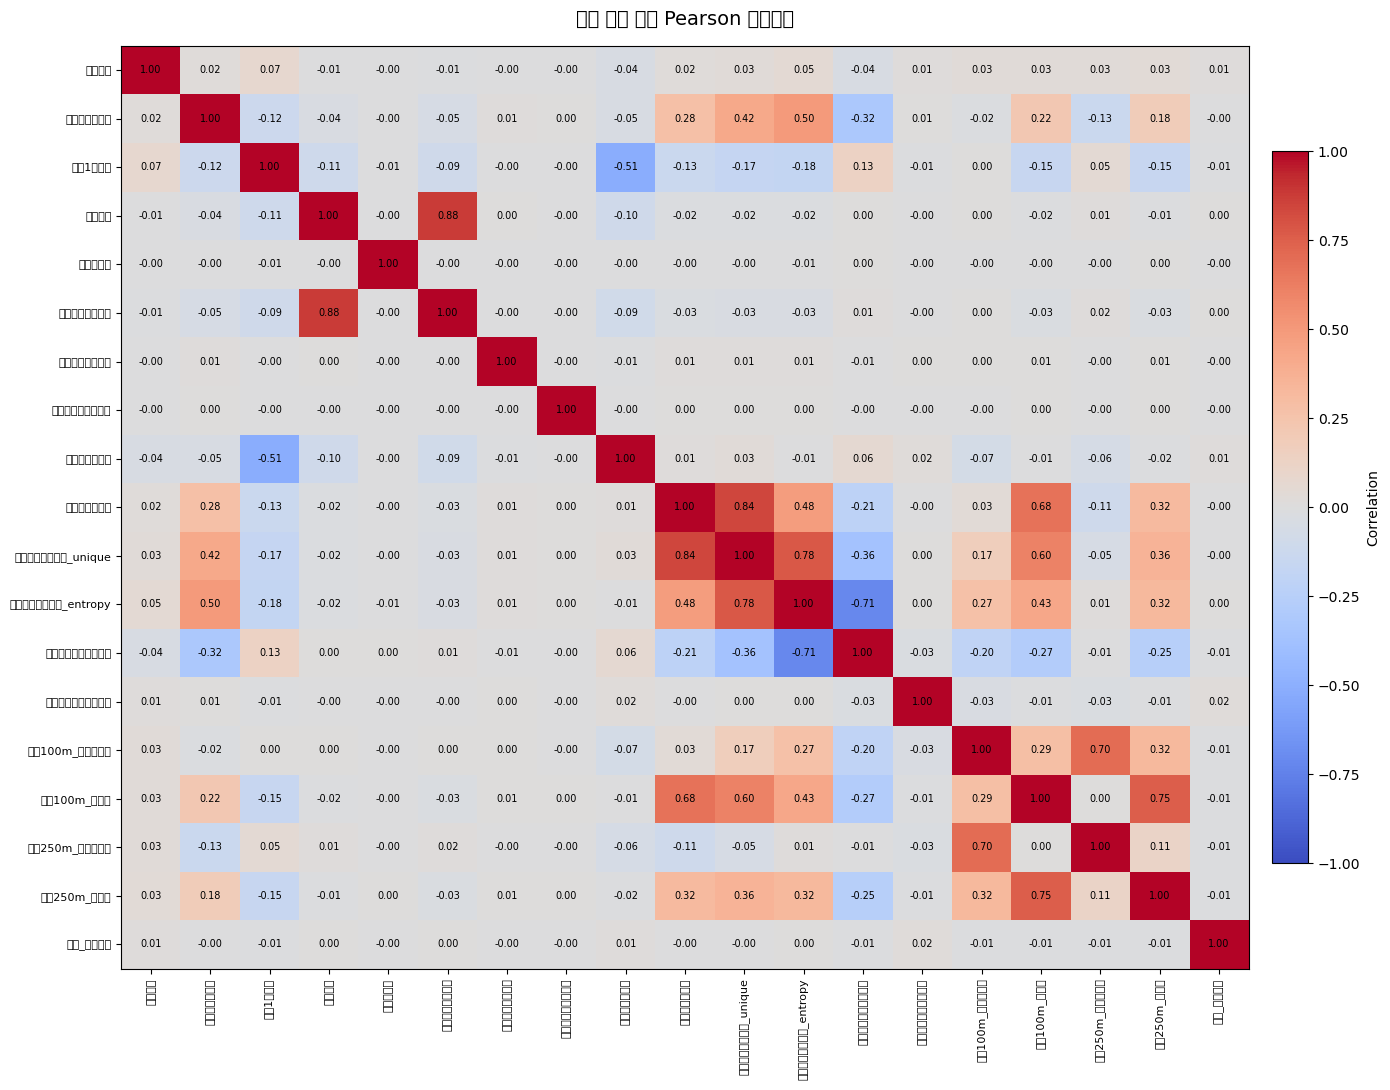

후보 설명변수 중 |Pearson r| >= 0.80인 변수쌍: 2개


,변수1,변수2,상관계수,절대상관계수
0,지하여부,지하층수미상여부,0.879955,0.879955
1,건물내총업소수,건물내업종다양성_unique,0.842793,0.842793


In [10]:
TARGET = TARGET_COL

candidate_cols = [
    '지점여부', '건물명존재여부', '지상1층여부', '지하여부', '반지하여부',
    '지하층수미상여부', '층호결합추정여부', '층정보파싱실패여부', '층정보결측여부',
    '건물내총업소수', '건물내업종다양성_unique', '건물내업종다양성_entropy',
    '건물내표본수부족여부', '건물관리번호결측여부',
    '반경100m_업종다양성', '반경100m_이웃수', '반경250m_업종다양성', '반경250m_이웃수',
    '1단계_위험점수',
    TARGET
]

existing_candidate_cols = [c for c in candidate_cols if c in df.columns]
missing_candidate_cols = [c for c in candidate_cols if c not in df.columns]
print('사용할 후보 컬럼:', existing_candidate_cols)
if missing_candidate_cols:
    print('현재 데이터에 없는 컬럼 (1단계 결합 전이면 정상):', missing_candidate_cols)

candidate_df = df[existing_candidate_cols].copy()
pearson_candidate = candidate_df.corr(method='pearson')
plot_corr_heatmap(pearson_candidate, '모델 후보 변수 Pearson 상관관계', figsize=(14, 11), annotate=True)

feature_cols = [c for c in existing_candidate_cols if c != TARGET]
feature_corr = df[feature_cols].corr(method='pearson')
high_corr_features = get_high_corr_pairs(feature_corr, threshold=CORR_THRESHOLD)
print(f'후보 설명변수 중 |Pearson r| >= {CORR_THRESHOLD:.2f}인 변수쌍: {len(high_corr_features)}개')
display(high_corr_features)


### 타깃과의 단변량 상관관계

In [11]:
target_corr = pd.DataFrame({
    'Pearson': df[numeric_cols_all].corr(method='pearson')[TARGET],
    'Spearman': df[numeric_cols_all].corr(method='spearman')[TARGET]
}).drop(index=TARGET, errors='ignore')

target_corr['|Pearson|'] = target_corr['Pearson'].abs()
target_corr['|Spearman|'] = target_corr['Spearman'].abs()
target_corr = target_corr.sort_values('|Pearson|', ascending=False)
display(target_corr)

candidate_target_corr = target_corr.loc[
    [c for c in feature_cols if c in target_corr.index]
].sort_values('|Pearson|', ascending=False)
display(candidate_target_corr)


,Pearson,Spearman,|Pearson|,|Spearman|
건물관리번호결측여부,0.022823,0.022823,0.022823,0.022823
반경100m_업종다양성,-0.014289,-0.007736,0.014289,0.007736
지점여부,0.013899,0.013899,0.013899,0.013899
반경250m_이웃수,-0.011966,-0.011847,0.011966,0.011847
건물내표본수부족여부,-0.011256,-0.011256,0.011256,0.011256
경도,-0.009867,-0.005911,0.009867,0.005911
층정보결측여부,0.009383,0.009383,0.009383,0.009383
반경250m_업종다양성,-0.009357,-0.003203,0.009357,0.003203
지상1층여부,-0.008949,-0.008949,0.008949,0.008949
구우편번호,0.008813,0.007159,0.008813,0.007159


,Pearson,Spearman,|Pearson|,|Spearman|
건물관리번호결측여부,0.022823,0.022823,0.022823,0.022823
반경100m_업종다양성,-0.014289,-0.007736,0.014289,0.007736
지점여부,0.013899,0.013899,0.013899,0.013899
반경250m_이웃수,-0.011966,-0.011847,0.011966,0.011847
건물내표본수부족여부,-0.011256,-0.011256,0.011256,0.011256
층정보결측여부,0.009383,0.009383,0.009383,0.009383
반경250m_업종다양성,-0.009357,-0.003203,0.009357,0.003203
지상1층여부,-0.008949,-0.008949,0.008949,0.008949
반경100m_이웃수,-0.008710,-0.008756,0.008710,0.008756
건물내업종다양성_entropy,0.004683,0.005316,0.004683,0.005316


In [12]:
OUTPUT_DIR_B = BASE_DIR
OUTPUT_DIR_B.mkdir(exist_ok=True)

pearson_all.to_csv(OUTPUT_DIR_B / 'pearson_all_numeric.csv', encoding='utf-8-sig')
spearman_all.to_csv(OUTPUT_DIR_B / 'spearman_all_numeric.csv', encoding='utf-8-sig')
high_corr_all.to_csv(OUTPUT_DIR_B / 'high_corr_pairs_all_numeric.csv', index=False, encoding='utf-8-sig')
pearson_candidate.to_csv(OUTPUT_DIR_B / 'pearson_candidate_features.csv', encoding='utf-8-sig')
high_corr_features.to_csv(OUTPUT_DIR_B / 'high_corr_pairs_candidate_features.csv', index=False, encoding='utf-8-sig')
target_corr.to_csv(OUTPUT_DIR_B / 'target_correlations_all_numeric.csv', encoding='utf-8-sig')
print('저장 완료:', OUTPUT_DIR_B.resolve())


저장 완료: .\data


## Part C. 상관관계 기반 컬럼 삭제

In [13]:
DROP_COLS_C = ["지하층수미상여부", "건물내업종다양성_unique"]
OUTPUT_PATH_C = BASE_DIR / "2단계_학습데이터_전처리완료.csv.gz"

existing_drop_cols = [c for c in DROP_COLS_C if c in df.columns]
missing_drop_cols = [c for c in DROP_COLS_C if c not in df.columns]

if missing_drop_cols:
    print(f"[주의] 이미 없는 컬럼: {missing_drop_cols}")

df = df.drop(columns=existing_drop_cols)
print(f"드롭 완료: {existing_drop_cols}")
print(f"남은 컬럼 수: {df.shape[1]}")

df.to_csv(OUTPUT_PATH_C, index=False, encoding="utf-8-sig", compression="gzip")
print(f"저장 완료: {OUTPUT_PATH_C}")


드롭 완료: ['지하층수미상여부', '건물내업종다양성_unique']
남은 컬럼 수: 54
저장 완료: .\data\2단계_학습데이터_전처리완료.csv.gz


## Part C-2. 2단계 데이터에 1단계 위험점수 결합

In [15]:
%pip install geopandas
import geopandas as gpd

STAGE1_PATH = BASE_DIR / "stage1_risk_score_table.csv"
BOUNDARY_PATH = BASE_DIR / "boundary.shp"
CROSSWALK_PATH_STAGE1 = BASE_DIR / "업종_대응표_최종_v3.csv"
SERVICE_LOOKUP_PATH_STAGE1 = BASE_DIR / "서비스업종_코드명_룩업.csv"
OUTPUT_PATH_C2 = BASE_DIR / "2단계_학습데이터_1단계결합완료.csv.gz"

MAX_NEAREST_DISTANCE = 100  


### 상권_코드 공간조인

In [16]:
def join_stage2_with_boundary(df_in: pd.DataFrame, boundary_path: str, max_nearest_distance: float = 100) -> pd.DataFrame:
    boundary = gpd.read_file(boundary_path, encoding="utf-8")
    boundary = boundary.rename(columns={"TRDAR_CD": "상권_코드"})
    boundary["상권_코드"] = boundary["상권_코드"].astype(int)
    boundary["면적"] = boundary.geometry.area

    df_ = df_in.copy()
    df_["_row_id"] = range(len(df_))

    stores = gpd.GeoDataFrame(
        df_, geometry=gpd.points_from_xy(df_["경도"], df_["위도"]), crs="EPSG:4326"
    ).to_crs(boundary.crs)

    joined = gpd.sjoin(stores, boundary[["상권_코드", "면적", "geometry"]], how="left", predicate="within")
    joined = joined.sort_values("면적").drop_duplicates(subset="_row_id", keep="first")
    joined = joined.sort_values("_row_id").reset_index(drop=True)
    joined["상권코드_매칭방식"] = joined["상권_코드"].notna().map({True: "직접매칭", False: None})

    unmatched_mask = joined["상권_코드"].isna()
    if unmatched_mask.sum() > 0:
        unmatched = joined.loc[unmatched_mask, ["_row_id", "geometry"]]
        unmatched_gdf = gpd.GeoDataFrame(unmatched, geometry="geometry", crs=boundary.crs)
        nearest = gpd.sjoin_nearest(
            unmatched_gdf, boundary[["상권_코드", "geometry"]],
            how="left", max_distance=max_nearest_distance, distance_col="거리"
        ).drop_duplicates(subset="_row_id", keep="first")
        nearest_map = nearest.set_index("_row_id")["상권_코드"]
        recovered_ids = nearest_map.dropna().index
        joined.loc[joined["_row_id"].isin(recovered_ids), "상권_코드"] = (
            joined.loc[joined["_row_id"].isin(recovered_ids), "_row_id"].map(nearest_map)
        )
        joined.loc[joined["_row_id"].isin(recovered_ids), "상권코드_매칭방식"] = "최근접매칭"

    joined["상권코드_매칭방식"] = joined["상권코드_매칭방식"].fillna("매칭실패")
    result_ = joined.drop(columns=["geometry", "index_right", "면적", "_row_id"], errors="ignore")
    return pd.DataFrame(result_)


### 업종 크로스워크 적용

In [17]:
def apply_industry_crosswalk(df_in: pd.DataFrame, crosswalk_path: str, service_lookup_path: str) -> pd.DataFrame:
    cross = pd.read_csv(crosswalk_path)
    lookup = pd.read_csv(service_lookup_path)
    name_to_code = dict(zip(lookup["서비스_업종_코드_명"], lookup["서비스_업종_코드"]))

    df_ = df_in.copy()
    df_ = df_.merge(
        cross[["상권업종소분류명", "최종_매핑", "처리방침"]],
        on="상권업종소분류명", how="left"
    )

    is_usable = df_["처리방침"].isin(["직접매칭", "근사매칭"])
    df_["서비스_업종_코드"] = None
    df_.loc[is_usable, "서비스_업종_코드"] = df_.loc[is_usable, "최종_매핑"].map(name_to_code)

    df_["업종매칭방식"] = "매칭실패"
    df_.loc[is_usable & df_["서비스_업종_코드"].notna(), "업종매칭방식"] = df_.loc[is_usable & df_["서비스_업종_코드"].notna(), "처리방침"]

    df_ = df_.drop(columns=["최종_매핑", "처리방침"], errors="ignore")
    return df_


def to_int_quarter(q_str: str) -> int:
    year, q = q_str.split("Q")
    return int(year) * 10 + int(q)


### 전체 파이프라인

In [18]:
def merge_stage1_risk_score(
    df_in: pd.DataFrame,
    stage1_path: str,
    boundary_path: str,
    crosswalk_path: str,
    service_lookup_path: str,
    max_nearest_distance: float = 100,
) -> pd.DataFrame:
    df_ = df_in
    n_total = len(df_)

    df_ = join_stage2_with_boundary(df_, boundary_path, max_nearest_distance)
    df_["1단계_공간매칭실패여부"] = (df_["상권코드_매칭방식"] == "매칭실패").astype(int)
    n_district_fail = df_["1단계_공간매칭실패여부"].sum()
    print(f"[상권_코드 결합] 매칭실패 {n_district_fail}건 / 전체 {n_total}건 ({n_district_fail/n_total*100:.2f}%)")

    df_ = apply_industry_crosswalk(df_, crosswalk_path, service_lookup_path)
    df_["1단계_업종매칭실패여부"] = (df_["업종매칭방식"] == "매칭실패").astype(int)
    n_industry_fail = df_["1단계_업종매칭실패여부"].sum()
    print(f"[업종 결합] 매칭실패 {n_industry_fail}건 / 전체 {n_total}건 ({n_industry_fail/n_total*100:.2f}%)")

    df_["기준_년분기_int"] = df_["기준_년분기"].apply(to_int_quarter)
    stage1 = pd.read_csv(
        stage1_path,
        usecols=["상권_코드", "서비스_업종_코드", "예측_대상_분기", "예측_폐업위험점수"]
    )
    df_ = df_.merge(
        stage1,
        left_on=["상권_코드", "서비스_업종_코드", "기준_년분기_int"],
        right_on=["상권_코드", "서비스_업종_코드", "예측_대상_분기"],
        how="left"
    )
    df_ = df_.rename(columns={"예측_폐업위험점수": "1단계_위험점수"})

    df_["1단계_위험점수대체수준"] = 0
    df_.loc[df_["1단계_위험점수"].isna(), "1단계_위험점수대체수준"] = pd.NA

    n_score_fail = df_["1단계_위험점수"].isna().sum()
    print(f"[1단계 위험점수 결합] 매칭실패(=결측) {n_score_fail}건 / 전체 {n_total}건 ({n_score_fail/n_total*100:.2f}%)")

    district_median = df_.groupby(["상권_코드", "기준_년분기"])["1단계_위험점수"].transform("median")
    tier1_mask = df_["1단계_위험점수"].isna() & district_median.notna()
    df_.loc[tier1_mask, "1단계_위험점수대체수준"] = 1
    df_["1단계_위험점수"] = df_["1단계_위험점수"].fillna(district_median)
    n_after_district_fill = df_["1단계_위험점수"].isna().sum()

    quarter_median = df_.groupby("기준_년분기")["1단계_위험점수"].transform("median")
    tier2_mask = df_["1단계_위험점수"].isna() & quarter_median.notna()
    df_.loc[tier2_mask, "1단계_위험점수대체수준"] = 2
    df_["1단계_위험점수"] = df_["1단계_위험점수"].fillna(quarter_median)
    n_final_na = df_["1단계_위험점수"].isna().sum()

    print(f"[채움] 상권+분기 median으로 {n_score_fail - n_after_district_fill}건 채움(대체수준=1) "
          f"-> 분기 median으로 {n_after_district_fill - n_final_na}건 추가 채움(대체수준=2) "
          f"-> 최종 잔여 NaN {n_final_na}건 (보통 1단계 예측범위 밖 분기, 예: 2025년 - 대체수준도 NA로 남음)")

    df_ = df_.drop(columns=["예측_대상_분기", "기준_년분기_int"], errors="ignore")
    return df_


### 실행

In [1]:
result = merge_stage1_risk_score(
    df,
    stage1_path=STAGE1_PATH,
    boundary_path=BOUNDARY_PATH,
    crosswalk_path=CROSSWALK_PATH_STAGE1,
    service_lookup_path=SERVICE_LOOKUP_PATH_STAGE1,
    max_nearest_distance=MAX_NEAREST_DISTANCE,
)

print()
print("1단계_위험점수대체수준 분포:")
print(result["1단계_위험점수대체수준"].value_counts(dropna=False))

result.to_csv(OUTPUT_PATH_C2, index=False, encoding="utf-8-sig", compression="gzip")
print(f"저장 완료: {OUTPUT_PATH_C2}")


## Part D. 인허가데이터 - 결합 전 준비 (정제 + 검증)

In [2]:
LICENSE_RAW_PATH = BASE_DIR / 'final_8industries.csv' 

KEEP_COLS_LICENSE = [
    '관리번호', '업종_대분류', '좌표정보(X)', '좌표정보(Y)', '사업장명',
    '지번주소', '도로명주소',                                  
    '인허가일자', '영업상태명', '폐업일자',
    '인허가취소일자', '휴업시작일자', '휴업종료일자', '재개업일자', '최종수정일자',
]


def clean_date_col(s: pd.Series) -> pd.Series:
    s = s.astype('string').str.strip().replace('', pd.NA)
    return pd.to_datetime(s, format='%Y-%m-%d', errors='coerce')


def normalize_store_name(value):
    if pd.isna(value):
        return ""
    value = unicodedata.normalize("NFKC", str(value)).lower().strip()
    value = re.sub(r"주식회사|유한회사|㈜|\(주\)|사단법인|재단법인", "", value)
    value = re.sub(r"[^0-9a-z가-힣]", "", value)
    return value


def normalize_address(value):
    if pd.isna(value):
        return ""
    value = unicodedata.normalize("NFKC", str(value)).strip()
    value = re.sub(r"\([^)]*\)", "", value)                 
    value = re.sub(r"(지하|지상)?\s*\d+층.*$", "", value)     
    value = re.sub(r"\d+~\d+호.*$", "", value)              
    value = re.sub(r"\s+", "", value)                       
    value = re.sub(r"[^0-9a-zA-Z가-힣]", "", value)          
    return value


lic = pd.read_csv(LICENSE_RAW_PATH, encoding='utf-8-sig', usecols=KEEP_COLS_LICENSE, dtype=str)
print(f'로드 완료: {lic.shape[0]:,}행 x {lic.shape[1]}컬럼')


In [ ]:
DATE_COLS_LICENSE = ['인허가일자', '폐업일자', '인허가취소일자', '휴업시작일자',
                      '휴업종료일자', '재개업일자', '최종수정일자']
for col in DATE_COLS_LICENSE:
    lic[col] = clean_date_col(lic[col])
print(lic[DATE_COLS_LICENSE].isna().sum())

lic = lic.dropna(subset=['인허가일자']).reset_index(drop=True)


### 좌표 숫자형 변환 + 좌표계 통일 (EPSG:5174 -> 5181)

In [ ]:
from pyproj import Transformer

lic['좌표정보(X)'] = pd.to_numeric(lic['좌표정보(X)'].str.strip(), errors='coerce')
lic['좌표정보(Y)'] = pd.to_numeric(lic['좌표정보(Y)'].str.strip(), errors='coerce')

coord_missing = lic[['좌표정보(X)', '좌표정보(Y)']].isna().any(axis=1)
print(f'좌표 결측: {coord_missing.sum():,}건 ({coord_missing.mean()*100:.1f}%) - 좌표기반 매칭 대상에서만 제외됨 (주소매칭은 가능)')

transformer5174to5181 = Transformer.from_crs('EPSG:5174', 'EPSG:5181', always_xy=True)
has_coord = ~coord_missing
x5181, y5181 = transformer5174to5181.transform(
    lic.loc[has_coord, '좌표정보(X)'].values, lic.loc[has_coord, '좌표정보(Y)'].values
)
lic.loc[has_coord, '좌표_X_5181'] = x5181
lic.loc[has_coord, '좌표_Y_5181'] = y5181

lic['도로명주소_정규화'] = lic['도로명주소'].map(normalize_address)
lic['지번주소_정규화'] = lic['지번주소'].map(normalize_address)
lic['상호명_정규화'] = lic['사업장명'].map(normalize_store_name)

print(f'인허가데이터 매칭후보: {len(lic):,}건')


### 관리번호 중복 확인

In [ ]:
dup_ids = lic.loc[lic['관리번호'].duplicated(keep=False), '관리번호']
print(f'중복 관리번호 그룹 수: {dup_ids.nunique()}건 (전체 {len(lic):,}행 중 극소수)')

lic['인허가_레코드_ID'] = lic.index.astype(str) + '_' + lic['업종_대분류'].astype(str)

lic['업종_대분류'] = lic['업종_대분류'].astype('category')
lic['영업상태명'] = lic['영업상태명'].astype('category')
print(f'메모리 사용량: {lic.memory_usage(deep=True).sum()/1e6:.1f} MB')


## Part E. 인허가데이터 매칭 (주소 + 상호명 유사도 + 좌표 등급 매칭, v2)

In [ ]:
from rapidfuzz import fuzz
from sklearn.neighbors import BallTree

STAGE2_MATCHING_INPUT_PATH = BASE_DIR / '2단계_학습데이터_1단계결합완료.csv.gz'  
CROSSWALK_PATH = BASE_DIR / '인허가_소진공_업종매핑_v3.csv'
OUTPUT_PATH_E = BASE_DIR / '2단계_학습데이터_인허가결합완료_v2.csv.gz'

COL_STORE_ID = '상가업소번호'
COL_QUARTER = '기준_년분기'
COL_STORE_NAME = '상호명'
COL_INDUSTRY_RAW = '상권업종소분류명'
COL_ROAD_ADDR = '도로명주소'
COL_JIBUN_ADDR = '지번주소'
COL_LON = '경도'
COL_LAT = '위도'

COORD_RADIUS_C = 10   
COORD_RADIUS_D = 30   
NAME_SCORE_HIGH = 90  
NAME_SCORE_MID = 80   
MIN_CONFIDENCE = ['높음', '중간']

def name_similarity(name1, name2):
    n1, n2 = normalize_store_name(name1), normalize_store_name(name2)
    if not n1 or not n2:
        return 0.0
    return fuzz.ratio(n1, n2)


In [ ]:
stage2 = pd.read_csv(
    STAGE2_MATCHING_INPUT_PATH, dtype={COL_STORE_ID: str, COL_QUARTER: str},
    usecols=[COL_STORE_ID, COL_QUARTER, COL_STORE_NAME, COL_INDUSTRY_RAW,
             COL_ROAD_ADDR, COL_JIBUN_ADDR, COL_LON, COL_LAT],
)
n_total_stores = stage2[COL_STORE_ID].nunique()
print(f'2단계 고유 매장 수: {n_total_stores:,}')

stores = (
    stage2.sort_values([COL_STORE_ID, COL_QUARTER])
    .groupby(COL_STORE_ID)
    .agg(
        최초관측분기=(COL_QUARTER, 'first'),
        상호명=(COL_STORE_NAME, 'first'),
        도로명주소=(COL_ROAD_ADDR, 'first'),
        지번주소=(COL_JIBUN_ADDR, 'first'),
        경도=(COL_LON, 'first'),
        위도=(COL_LAT, 'first'),
        상권업종소분류명=(COL_INDUSTRY_RAW, lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan),
    )
    .reset_index()
)

stores['도로명주소_정규화'] = stores['도로명주소'].map(normalize_address)
stores['지번주소_정규화'] = stores['지번주소'].map(normalize_address)
stores['상호명_정규화'] = stores['상호명'].map(normalize_store_name)

cross = pd.read_csv(CROSSWALK_PATH)
cross_usable = cross[cross['인허가_업종매핑'] != '매칭실패']
if MIN_CONFIDENCE:
    cross_usable = cross_usable[cross_usable['확신도'].isin(MIN_CONFIDENCE)]
name_to_industry = dict(zip(cross_usable['상권업종소분류명'], cross_usable['인허가_업종매핑']))
stores['인허가_업종매핑'] = stores['상권업종소분류명'].map(name_to_industry)

has_coord = stores['경도'].notna() & stores['위도'].notna()
transformer4326to5181 = Transformer.from_crs('EPSG:4326', 'EPSG:5181', always_xy=True)
x5181, y5181 = transformer4326to5181.transform(
    stores.loc[has_coord, '경도'].values, stores.loc[has_coord, '위도'].values
)
stores.loc[has_coord, '좌표_X_5181'] = x5181
stores.loc[has_coord, '좌표_Y_5181'] = y5181


### 후보 생성 (도로명 -> 지번 -> 좌표 순)

In [ ]:
def build_address_candidates(stores_df, lic_df, addr_col):
    s = stores_df[stores_df[addr_col] != ''][[COL_STORE_ID, addr_col, '상호명_정규화']]
    l = lic_df[lic_df[addr_col] != ''][['관리번호', addr_col, '상호명_정규화',
                                          '인허가일자', '폐업일자', '영업상태명', '업종_대분류',
                                          '좌표_X_5181', '좌표_Y_5181']]
    merged = s.merge(l, on=addr_col, suffixes=('_store', '_lic'))
    return merged


road_cand = build_address_candidates(stores, lic, '도로명주소_정규화')
road_cand['매칭경로'] = '도로명'
print(f'도로명주소 정확일치 후보: {len(road_cand):,}건 (매장 {road_cand[COL_STORE_ID].nunique():,}개)')

jibun_cand = build_address_candidates(stores, lic, '지번주소_정규화')
jibun_cand['매칭경로'] = '지번'
print(f'지번주소 정확일치 후보: {len(jibun_cand):,}건 (매장 {jibun_cand[COL_STORE_ID].nunique():,}개)')


In [ ]:
coord_rows = []
target = stores.dropna(subset=['좌표_X_5181', '좌표_Y_5181', '인허가_업종매핑'])

for industry, grp in target.groupby('인허가_업종매핑'):
    lic_grp = lic[(lic['업종_대분류'] == industry) & lic['좌표_X_5181'].notna()].reset_index(drop=True)
    if len(lic_grp) == 0 or len(grp) == 0:
        continue
    tree = BallTree(lic_grp[['좌표_X_5181', '좌표_Y_5181']].values, metric='euclidean')
    ind, dist = tree.query_radius(grp[['좌표_X_5181', '좌표_Y_5181']].values, r=COORD_RADIUS_D, return_distance=True)

    grp = grp.reset_index(drop=True)
    for i in range(len(grp)):
        for j, d in zip(ind[i], dist[i]):
            coord_rows.append({
                COL_STORE_ID: grp.loc[i, COL_STORE_ID],
                '상호명_정규화_store': grp.loc[i, '상호명_정규화'],
                '관리번호': lic_grp.loc[j, '관리번호'],
                '상호명_정규화_lic': lic_grp.loc[j, '상호명_정규화'],
                '인허가일자': lic_grp.loc[j, '인허가일자'],
                '폐업일자': lic_grp.loc[j, '폐업일자'],
                '영업상태명': lic_grp.loc[j, '영업상태명'],
                '업종_대분류': lic_grp.loc[j, '업종_대분류'],
                '거리': d,
            })

coord_cand = pd.DataFrame(coord_rows)
coord_cand['매칭경로'] = '좌표'
print(f'좌표 반경 {COORD_RADIUS_D}m 내 후보: {len(coord_cand):,}건 (매장 {coord_cand[COL_STORE_ID].nunique():,}개)')


### 상호명 유사도 계산 + 등급(A~D) 산정

In [ ]:
def add_name_score(df_in):
    df_ = df_in.copy()
    df_['상호명유사도'] = [
        fuzz.ratio(a, b) if a and b else 0.0
        for a, b in zip(df_['상호명_정규화_store'], df_['상호명_정규화_lic'])
    ]
    return df_

road_cand = add_name_score(road_cand)
jibun_cand = add_name_score(jibun_cand)
coord_cand = add_name_score(coord_cand)

road_cand['거리'] = 0.0
jibun_cand['거리'] = 0.0

industry_map = dict(zip(stores[COL_STORE_ID], stores['인허가_업종매핑']))
road_cand['업종일치'] = road_cand[COL_STORE_ID].map(industry_map) == road_cand['업종_대분류']
jibun_cand['업종일치'] = jibun_cand[COL_STORE_ID].map(industry_map) == jibun_cand['업종_대분류']
coord_cand['업종일치'] = True

use_cols = [COL_STORE_ID, '관리번호', '매칭경로', '거리', '상호명유사도',
            '업종일치', '인허가일자', '폐업일자', '영업상태명']
all_cand = pd.concat([road_cand[use_cols], jibun_cand[use_cols], coord_cand[use_cols]], ignore_index=True)


def determine_grade(row):
    if row['매칭경로'] == '도로명' and row['상호명유사도'] >= NAME_SCORE_HIGH:
        return 'A'
    if row['매칭경로'] == '지번' and row['상호명유사도'] >= NAME_SCORE_HIGH:
        return 'B'
    if row['거리'] <= COORD_RADIUS_C and row['상호명유사도'] >= NAME_SCORE_MID:
        return 'C'
    if row['거리'] <= COORD_RADIUS_D and row['상호명유사도'] >= NAME_SCORE_MID and row['업종일치']:
        return 'D'
    return 'E'

all_cand['등급'] = all_cand.apply(determine_grade, axis=1)
all_cand = all_cand[all_cand['등급'] != 'E'].copy() 

print(all_cand['등급'].value_counts())
print(f'등급 A~D를 하나라도 받은 매장 수: {all_cand[COL_STORE_ID].nunique():,} / {n_total_stores:,} '
      f'({all_cand[COL_STORE_ID].nunique()/n_total_stores*100:.1f}%)')


### 분기별 시간 유효성 검증 + 최종 후보 선택 (핵심 - 시간버그 수정 부분)

In [ ]:
def quarter_to_start_date(q):
    year = int(str(q)[:4]); qtr = int(str(q)[-1])
    month = (qtr - 1) * 3 + 1
    return pd.Timestamp(year=year, month=month, day=1)

candidate_stores = all_cand[COL_STORE_ID].unique()
stage2_sub = stage2[stage2[COL_STORE_ID].isin(candidate_stores)][[COL_STORE_ID, COL_QUARTER]]

merged = stage2_sub.merge(all_cand, on=COL_STORE_ID, how='left')
merged['기준일'] = merged[COL_QUARTER].map(quarter_to_start_date)

merged['시간유효'] = (
    (merged['인허가일자'] <= merged['기준일']) &
    (merged['폐업일자'].isna() | (merged['폐업일자'] > merged['기준일']))
)

grade_rank = {'A': 0, 'B': 1, 'C': 2, 'D': 3}
merged['등급순위'] = merged['등급'].map(grade_rank)
merged['시간유효_순위'] = (~merged['시간유효']).astype(int)

merged_sorted = merged.sort_values(
    [COL_STORE_ID, COL_QUARTER, '시간유효_순위', '등급순위', '상호명유사도'],
    ascending=[True, True, True, True, False]
)
best = merged_sorted.drop_duplicates(subset=[COL_STORE_ID, COL_QUARTER], keep='first').copy()

invalid_mask = ~best['시간유효']
best.loc[invalid_mask, ['관리번호', '매칭경로', '등급', '거리', '상호명유사도',
                          '인허가일자', '폐업일자', '영업상태명']] = np.nan
best['매칭성공여부'] = best['관리번호'].notna().astype(int)

print(best['등급'].value_counts(dropna=False))
print(f'분기 기준 최종 매칭 성공: {best["매칭성공여부"].sum():,} / {len(best):,}건 '
      f'(시간조건 때문에 후보가 있었는데도 탈락한 건: {invalid_mask.sum():,}건)')


### 단계별 결측률 리포트

In [ ]:
n_total_panel_rows = len(stage2)
n_candidate_store_rows = len(stage2_sub)
n_final_matched = best['매칭성공여부'].sum()

print('===== 매칭 단계별 리포트 (분기-매장 행 기준) =====')
print(f'전체 (매장 x 분기) 행                        : {n_total_panel_rows:>10,} (100.0%)')
print(f'A~D 등급 후보를 하나라도 가진 매장의 행       : {n_candidate_store_rows:>10,} ({n_candidate_store_rows/n_total_panel_rows*100:5.1f}%)')
print(f'  -> 그 중 시간조건까지 통과한 최종 매칭      : {n_final_matched:>10,} ({n_final_matched/n_total_panel_rows*100:5.1f}%)')
print()
print('등급별 최종 채택 분포:')
print(best.loc[best['매칭성공여부']==1, '등급'].value_counts())


### 전체 패널에 결합 + 저장

In [ ]:
stage2_full = pd.read_csv(STAGE2_MATCHING_INPUT_PATH, dtype={COL_STORE_ID: str, COL_QUARTER: str})

result = stage2_full.merge(
    best[[COL_STORE_ID, COL_QUARTER, '관리번호', '등급', '매칭경로', '거리', '상호명유사도',
          '인허가일자', '폐업일자', '영업상태명', '매칭성공여부']],
    on=[COL_STORE_ID, COL_QUARTER], how='left'
)
result['매칭성공여부'] = result['매칭성공여부'].fillna(0).astype(int)

result.to_csv(OUTPUT_PATH_E, index=False, encoding='utf-8-sig', compression='gzip')
print(f'저장 완료: {OUTPUT_PATH_E}, shape={result.shape}')


## Part F. 인허가 피처 생성 + 라벨 검증

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

MATCHED_PATH = OUTPUT_PATH_E
LICENSE_RAW_PATH_F = LICENSE_RAW_PATH
COL_EXISTING_LABEL = '폐업_다음분기'

df_f = pd.read_csv(
    MATCHED_PATH,
    dtype={COL_STORE_ID: str, COL_QUARTER: str, '관리번호': str},
    parse_dates=['인허가일자', '폐업일자'],
)
print(f'로드: {df_f.shape}')


### 진실표 피처 생성

In [ ]:
df_f['인허가_업종매핑'] = df_f[COL_INDUSTRY_RAW].map(name_to_industry)
df_f['인허가매칭성공여부'] = df_f['매칭성공여부'].fillna(0).astype('int8')

df_f['인허가대상업종여부'] = (
    df_f['인허가_업종매핑'].notna() | (df_f['인허가매칭성공여부'] == 1)
).astype('int8')

df_f['매칭등급'] = df_f['등급']  

quarter_start = df_f[COL_QUARTER].map(quarter_to_start_date)
tenure_months = (
    (quarter_start.dt.year - df_f['인허가일자'].dt.year) * 12
    + (quarter_start.dt.month - df_f['인허가일자'].dt.month)
)
df_f['업력_개월'] = tenure_months.where(df_f['인허가매칭성공여부'] == 1)
df_f['업력관측여부'] = df_f['업력_개월'].notna().astype('int8')

print(pd.crosstab(
    [df_f['인허가대상업종여부'], df_f['인허가매칭성공여부']],
    df_f['업력관측여부']
))


### 라벨 검증

In [ ]:
STATUS_CLOSED = '폐업'
STATUS_TRANSFERRED = '제외/삭제/전출'

def next_quarter_str(q):
    year = int(str(q)[:4]); qtr = int(str(q)[-1])
    return f'{year+1}Q1' if qtr == 4 else f'{year}Q{qtr+1}'

next_start = df_f[COL_QUARTER].map(next_quarter_str).map(quarter_to_start_date)
next_next_start = df_f[COL_QUARTER].map(next_quarter_str).map(next_quarter_str).map(quarter_to_start_date)

is_real_closure = df_f['인허가매칭성공여부'].eq(1) & (df_f['영업상태명'] == STATUS_CLOSED) & df_f['폐업일자'].notna()

df_f['인허가기반_폐업_다음분기'] = (
    is_real_closure & (df_f['폐업일자'] > next_start) & (df_f['폐업일자'] <= next_next_start)
).astype('Int8')
df_f.loc[df_f['인허가매칭성공여부'] == 0, '인허가기반_폐업_다음분기'] = pd.NA  

comparable = df_f['인허가매칭성공여부'] == 1
existing = df_f[COL_EXISTING_LABEL].to_numpy()
verified = df_f['인허가기반_폐업_다음분기'].fillna(-1).to_numpy()  

conditions = [
    (existing == 1) & (verified == 1),
    (existing == 1) & (verified == 0),
    (existing == 0) & (verified == 1),
    (existing == 0) & (verified == 0),
]
choices = ['일치_폐업', '불일치_기존만폐업', '불일치_인허가만폐업', '일치_생존']
df_f['라벨_비교결과'] = np.select(conditions, choices, default='매칭불가')
df_f.loc[~comparable, '라벨_비교결과'] = '매칭불가'

print(df_f.loc[comparable, '라벨_비교결과'].value_counts(normalize=True))


### 시계열 파생 피처 (갭 안전 버전)

In [ ]:
def quarter_add(q, delta):
    year = int(str(q)[:4]); qtr = int(str(q)[-1])
    total = year * 4 + (qtr - 1) + delta
    return f'{total // 4}Q{total % 4 + 1}'


def add_gap_safe_diff_features(data, id_col, quarter_col, cols):
    data = data.copy()

    dup_mask = data.duplicated(subset=[id_col, quarter_col], keep=False)
    if dup_mask.any():
        raise ValueError(
            f'{id_col}+{quarter_col} 조합이 중복된 행이 {dup_mask.sum():,}건 있습니다. '
            f'diff 피처 계산 전에 원인(보통 다른 컬럼과의 merge 과정에서 발생)을 먼저 해결하세요.'
        )

    lookup = data[[id_col, quarter_col] + cols].rename(
        columns={quarter_col: '_prev_q', **{c: f'{c}_prev' for c in cols}}
    )
    key = pd.DataFrame({
        id_col: data[id_col].values,
        '_prev_q': data[quarter_col].map(lambda q: quarter_add(q, -1)).values,
    })
    prev_vals = key.merge(lookup, on=[id_col, '_prev_q'], how='left')
    assert len(prev_vals) == len(data), '내부 merge에서 행 수가 바뀜 - lookup 키 중복 의심'

    for c in cols:
        prev = prev_vals[f'{c}_prev'].to_numpy()
        cur = data[c].to_numpy()
        data[f'{c}_diff1'] = (cur - prev).astype('float32')
        data[f'{c}_pct1'] = ((cur - prev) / (prev + 1.0)).astype('float32')
    return data


def add_service_prev_quarter_rate(data, service_col, quarter_col, target_col):
    data = data.copy()
    agg = data.groupby([service_col, quarter_col])[target_col].mean().reset_index()
    agg = agg.rename(columns={quarter_col: '_target_q', target_col: '업종_직전분기_폐업률'})

    key = pd.DataFrame({
        service_col: data[service_col].values,
        '_target_q': data[quarter_col].map(lambda q: quarter_add(q, -1)).values,
    })
    merged = key.merge(agg, on=[service_col, '_target_q'], how='left')
    data['업종_직전분기_폐업률'] = merged['업종_직전분기_폐업률'].to_numpy()
    return data


DIFF_TARGET_COLS = [
    '1단계_위험점수', '반경100m_이웃수', '반경250m_이웃수',
    '건물내총업소수', '반경100m_업종다양성',
]

df_f = df_f.sort_values([COL_STORE_ID, COL_QUARTER]).reset_index(drop=True)
df_f = add_gap_safe_diff_features(df_f, COL_STORE_ID, COL_QUARTER, DIFF_TARGET_COLS)

df_f['데이터내_누적분기수'] = (df_f.groupby(COL_STORE_ID)[COL_QUARTER].cumcount() + 1).astype('int16')
df_f['건물대비_100m이웃_비율'] = (df_f['반경100m_이웃수'] / (df_f['건물내총업소수'] + 1.0)).astype('float32')
df_f['업종다양성_대비_이웃수'] = (df_f['반경100m_이웃수'] / (df_f['반경100m_업종다양성'] + 0.001)).astype('float32')
df_f['1단계위험_x_100m이웃차이'] = (df_f['1단계_위험점수'] * df_f['반경100m_이웃수_diff1']).astype('float32')

if '서비스_업종_코드' in df_f.columns:
    df_f = add_service_prev_quarter_rate(df_f, '서비스_업종_코드', COL_QUARTER, COL_EXISTING_LABEL)

FEATURE_COLS_TIMESERIES = (
    [f'{c}_diff1' for c in DIFF_TARGET_COLS] + [f'{c}_pct1' for c in DIFF_TARGET_COLS]
    + ['데이터내_누적분기수', '건물대비_100m이웃_비율', '업종다양성_대비_이웃수',
       '1단계위험_x_100m이웃차이']
    + (['업종_직전분기_폐업률'] if '서비스_업종_코드' in df_f.columns else [])
)
print(f'시계열 파생 피처 {len(FEATURE_COLS_TIMESERIES)}개 생성 완료')


### 모델링용 컬럼 선별

In [ ]:
ID_COL = COL_STORE_ID
QUARTER_COL = COL_QUARTER
TARGET_COL_FINAL = COL_EXISTING_LABEL

DISTRICT_LOOKUP_PATH = BASE_DIR / '상권_코드명_룩업.csv'
SERVICE_LOOKUP_PATH = BASE_DIR / '서비스업종_코드명_룩업.csv'
TRAIN_OUTPUT_PATH_FINAL = BASE_DIR / '2단계_학습데이터_최종_인허가포함.csv.gz'
HOLDOUT_OUTPUT_PATH_FINAL = BASE_DIR / '2단계_2025홀드아웃_인허가포함.csv.gz'

FEATURE_COLS = [
    '지점여부', '건물명존재여부',
    '지상1층여부', '지하여부', '반지하여부',
    '층호결합추정여부', '층정보파싱실패여부', '층정보결측여부',
    '건물내총업소수', '건물내업종다양성_entropy',
    '건물내표본수부족여부', '건물관리번호결측여부',
    '반경100m_업종다양성', '반경100m_이웃수',
    '반경250m_업종다양성', '반경250m_이웃수',
    '1단계_위험점수',
    '1단계_공간매칭실패여부', '1단계_업종매칭실패여부',
]

FEATURE_COLS_LICENSE = [
    '업력_개월',
    '업력관측여부',
    '인허가대상업종여부',
    '인허가매칭성공여부',
]

META_COLS = ['상권_코드', '상권_코드_명', '서비스_업종_코드', '서비스_업종_코드_명']
META_COLS_LICENSE = ['관리번호', '매칭등급', '인허가일자', '폐업일자', '영업상태명',
                      '라벨_비교결과', '인허가기반_폐업_다음분기']


In [ ]:
district_lookup = pd.read_csv(DISTRICT_LOOKUP_PATH)
service_lookup = pd.read_csv(SERVICE_LOOKUP_PATH)

df_f = df_f.merge(district_lookup, on='상권_코드', how='left')
df_f = df_f.merge(service_lookup, on='서비스_업종_코드', how='left')

train_ready = df_f[df_f[QUARTER_COL] <= '2024Q4'].copy()
holdout_2025 = df_f[df_f[QUARTER_COL] >= '2025Q1'].copy()
print(f'학습 대상(~2024Q4): {len(train_ready):,}행 / 2025 홀드아웃: {len(holdout_2025):,}행')

na_before = train_ready['1단계_위험점수'].isna().sum()
if na_before > 0:
    print(f'[확인] 2024Q4 이하인데 1단계_위험점수가 NaN인 행 {na_before}건 발견 -> 삭제')
    train_ready = train_ready[train_ready['1단계_위험점수'].notna()].copy()
else:
    print('[확인] 2024Q4 이하 구간엔 1단계_위험점수 NaN 없음 - 정상')

print(f'참고 - 인허가매칭성공여부 분포:')
print(train_ready['인허가매칭성공여부'].value_counts(normalize=True))


In [ ]:
train_ready['1단계_위험점수대체수준'] = train_ready['1단계_위험점수대체수준'].astype('Int64')
dummies_stage1 = pd.get_dummies(train_ready['1단계_위험점수대체수준'], prefix='1단계_대체수준')
if '1단계_대체수준_0' in dummies_stage1.columns:
    dummies_stage1 = dummies_stage1.drop(columns=['1단계_대체수준_0'])
dummies_stage1 = dummies_stage1.astype(int)

dummies_grade = pd.get_dummies(train_ready['매칭등급'], prefix='매칭등급')
dummies_grade = dummies_grade.astype(int)

train_ready = pd.concat([train_ready, dummies_stage1, dummies_grade], axis=1)

DUMMY_COLS = list(dummies_stage1.columns)
DUMMY_COLS_LICENSE = list(dummies_grade.columns)
print('대체수준 원-핫:', DUMMY_COLS)
print('매칭등급 원-핫:', DUMMY_COLS_LICENSE)


In [ ]:
final_keep_cols = (
    [ID_COL, QUARTER_COL, TARGET_COL_FINAL]
    + META_COLS + META_COLS_LICENSE
    + FEATURE_COLS + DUMMY_COLS
    + FEATURE_COLS_LICENSE + DUMMY_COLS_LICENSE
    + FEATURE_COLS_TIMESERIES
)

missing_cols = [c for c in final_keep_cols if c not in train_ready.columns]
if missing_cols:
    raise ValueError(f'KEEP_COLS에 있는데 실제 df엔 없는 컬럼: {missing_cols}')

train_final = train_ready[final_keep_cols].copy()
print('최종 학습용 shape:', train_final.shape)
print(f'컬럼 수: 기존 {len([ID_COL, QUARTER_COL, TARGET_COL_FINAL]+META_COLS+FEATURE_COLS+DUMMY_COLS)}개 '
      f'+ 인허가 신규 {len(META_COLS_LICENSE+FEATURE_COLS_LICENSE+DUMMY_COLS_LICENSE)}개 '
      f'+ 시계열 신규 {len(FEATURE_COLS_TIMESERIES)}개 '
      f'= {len(final_keep_cols)}개')

train_final.to_csv(TRAIN_OUTPUT_PATH_FINAL, index=False, encoding='utf-8-sig', compression='gzip')
holdout_2025.to_csv(HOLDOUT_OUTPUT_PATH_FINAL, index=False, encoding='utf-8-sig', compression='gzip')
print(f'저장 완료: {TRAIN_OUTPUT_PATH_FINAL}, {HOLDOUT_OUTPUT_PATH_FINAL}')


## Part G. 로지스틱 회귀용 업력 대체 (TenureImputer) + 업력 효과 빠른 검증

In [ ]:
class TenureImputer(BaseEstimator, TransformerMixin):
    def __init__(self, tenure_col='업력_개월', industry_col='상권업종소분류명'):
        self.tenure_col = tenure_col
        self.industry_col = industry_col

    def fit(self, X, y=None):
        data = X.copy()
        self.industry_median_ = data.groupby(self.industry_col)[self.tenure_col].median()
        self.global_median_ = data[self.tenure_col].median()
        return self

    def transform(self, X):
        data = X.copy()
        data['업력관측여부'] = data[self.tenure_col].notna().astype('int8')
        industry_fill = data[self.industry_col].map(self.industry_median_)
        data[self.tenure_col] = (
            data[self.tenure_col].fillna(industry_fill).fillna(self.global_median_)
        )
        return data



### 업력의 순수 효과 검증 - 모델 2개 비교

In [ ]:
from scipy.stats import spearmanr

matched = df_f[df_f['인허가매칭성공여부'] == 1]
corr, p = spearmanr(matched['업력_개월'], matched[COL_EXISTING_LABEL])
print(f'[매칭성공분만] 업력_개월 vs 폐업_다음분기 Spearman: {corr:.4f} (p={p:.4g}), n={len(matched):,}')

corr2, p2 = spearmanr(
    df_f['인허가대상업종여부'].astype(float),
    df_f[COL_EXISTING_LABEL]
)
print(f'[전체] 인허가대상업종여부 vs 폐업_다음분기 Spearman: {corr2:.4f} (p={p2:.4g})')


In [ ]:
train_final.to_parquet(BASE_DIR / '2단계_학습데이터_최종_인허가포함_라벨보정.parquet', index=False)

## 요약

- **Part A**: `train_table.csv` 로드, 층수_숫자 드롭, 반경 업종다양성 0-fill, 건물내 다양성 분기평균 채움
- **Part B**: 상관관계 진단 (선택 실행) — 이 결과로 Part C의 삭제 대상을 정함
- **Part C**: `지하층수미상여부`, `건물내업종다양성_unique` 삭제 → `2단계_학습데이터_전처리완료.csv.gz`
- **Part D**: 인허가 원본 정제(날짜/좌표계 변환/정규화) + 관리번호 중복 검증
- **Part E**: 도로명/지번주소 + 상호명 유사도 + 좌표 기반 등급(A~D) 매칭, 분기별 시간유효성 검증
- **Part F**: 업력/대상업종/매칭성공 피처, 라벨 검증, 갭-세이프 시계열 파생피처, 2025 홀드아웃 분리
- **Part G**: TenureImputer (fold별 fit 필수), 업력 순수효과 빠른 검증
